# Predictive Maintenance for Engine Health
## Final Capstone — Machine Learning Deployment and Automation

**Learner:** Muthu Aravind  
**Project:** Capstone Project 3 — Predictive Maintenance  
**Dataset:** `data/engine_data.csv`, supplied through the capstone learning materials.

### Continuation of the submitted interim report
The interim report established the dataset registration, EDA, outlier treatment rationale, stratified split and initial model comparison. This final-phase notebook retains that work and adds a reproducible hyperparameter search, experiment tracking, final hold-out evaluation, model registration, Streamlit application checks and GitHub Actions workflow validation.

**Important label note:** the supplied data description does not establish whether class 0 or class 1 represents failure. Results are therefore reported using numeric class labels only.

## 1. Environment and repository setup
Run this notebook from the extracted `Predictive_Maintenance` repository root. The project ZIP includes the dataset, source modules, requirements, Streamlit app and GitHub Actions workflow.

In [1]:
from pathlib import Path
import sys, json, subprocess, warnings, textwrap, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
import sklearn, joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

possible_roots = [
    Path.cwd(),
    Path.cwd() / "Predictive_Maintenance",
    Path("/content/Predictive_Maintenance"),
    Path("/mnt/data/pm_audit/Predictive_Maintenance"),
]
ROOT = next((p.resolve() for p in possible_roots if (p / "data" / "engine_data.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Extract the GitHub project ZIP and run this notebook "
        "from the Predictive_Maintenance folder."
    )

SRC = ROOT / "src"
ARTIFACTS = ROOT / "artifacts"
FIGURES = ROOT / "reports" / "figures"
sys.path.insert(0, str(SRC))
FIGURES.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__, "| joblib:", joblib.__version__)
print("Dataset:", ROOT / "data" / "engine_data.csv")

Project root: /mnt/data/pm_audit/Predictive_Maintenance
Python: 3.13.5
pandas: 2.2.3 | NumPy: 2.3.5
scikit-learn: 1.8.0 | joblib: 1.5.3
Dataset: /mnt/data/pm_audit/Predictive_Maintenance/data/engine_data.csv


## 2. Data registration and validation
The validation module checks the expected seven-column schema, unique column names, non-empty input, numeric predictors and target, missing values, finite sensor values, and the presence of both binary classes.

In [2]:
from validate_data import validate_dataset, EXPECTED_COLUMNS, FEATURE_COLUMNS, TARGET

DATA_PATH = ROOT / "data" / "engine_data.csv"
validation_summary = validate_dataset(DATA_PATH)
df = pd.read_csv(DATA_PATH)
display(df.head())
print("Registered dataset shape:", df.shape)

DATA VALIDATION: PASSED
{
  "file": "/mnt/data/pm_audit/Predictive_Maintenance/data/engine_data.csv",
  "rows": 19535,
  "columns": 7,
  "predictor_columns": [
    "Engine rpm",
    "Lub oil pressure",
    "Fuel pressure",
    "Coolant pressure",
    "lub oil temp",
    "Coolant temp"
  ],
  "target": "Engine Condition",
  "missing_cells": 0,
  "duplicate_rows": 0,
  "target_counts": {
    "0": 7218,
    "1": 12317
  }
}


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.493592,11.790927,3.178981,84.144163,81.632187,1
1,876,2.941606,16.193866,2.464504,77.640934,82.445724,0
2,520,2.961746,6.553147,1.064347,77.752266,79.645777,1
3,473,3.707835,19.510172,3.727455,74.129907,71.774629,1
4,619,5.672919,15.738871,2.052251,78.396989,87.000225,0


Registered dataset shape: (19535, 7)


## 3. Data overview and quality assessment
The target distribution is moderately imbalanced. Missing values and exact duplicate rows are assessed before model training. No imputation or row deletion is applied because the supplied dataset contains no missing cells or exact duplicate rows.

,data_type,missing_values,distinct_values
Engine rpm,int64,0,1379
Lub oil pressure,float64,0,19534
Fuel pressure,float64,0,19531
Coolant pressure,float64,0,19534
lub oil temp,float64,0,19530
Coolant temp,float64,0,19532
Engine Condition,int64,0,2


,count,mean,std,min,25%,50%,75%,max
Engine rpm,19535.0,791.239,267.611,61.000,593.000,746.000,934.000,2239.000
Lub oil pressure,19535.0,3.304,1.022,0.003,2.519,3.162,4.055,7.266
Fuel pressure,19535.0,6.656,2.761,0.003,4.917,6.202,7.745,21.138
Coolant pressure,19535.0,2.335,1.036,0.002,1.600,2.167,2.849,7.479
lub oil temp,19535.0,77.643,3.111,71.322,75.726,76.817,78.072,89.581
Coolant temp,19535.0,78.427,6.207,61.673,73.895,78.347,82.915,195.528
Engine Condition,19535.0,0.631,0.483,0.000,0.000,1.000,1.000,1.000


,count,percentage
Engine Condition,,
0,7218,36.95
1,12317,63.05


Exact duplicate rows: 0


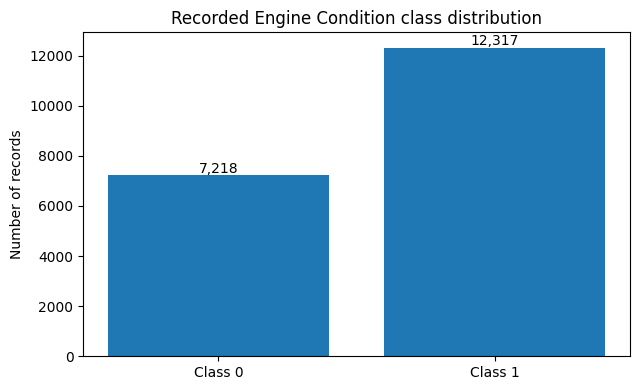

In [3]:
overview = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "distinct_values": df.nunique(),
})
display(overview)
display(df[EXPECTED_COLUMNS].describe().T.round(3))
class_summary = pd.DataFrame({
    "count": df[TARGET].value_counts().sort_index(),
    "percentage": (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2),
})
display(class_summary)
print("Exact duplicate rows:", int(df.duplicated().sum()))

fig, ax = plt.subplots(figsize=(6.5, 4))
class_counts = df[TARGET].value_counts().sort_index()
bars = ax.bar([f"Class {label}" for label in class_counts.index], class_counts.values)
ax.set_title("Recorded Engine Condition class distribution")
ax.set_ylabel("Number of records")
for bar, count in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100, f"{count:,}", ha="center")
fig.tight_layout()
display(fig)
fig.savefig(FIGURES / "class_distribution.png", dpi=180, bbox_inches="tight")
plt.close(fig)


## 4. Univariate exploratory analysis and outlier audit
Histograms and boxplots show each sensor's distribution and range. IQR fences are used to flag observations for review, not to automatically remove potentially valid operating states.

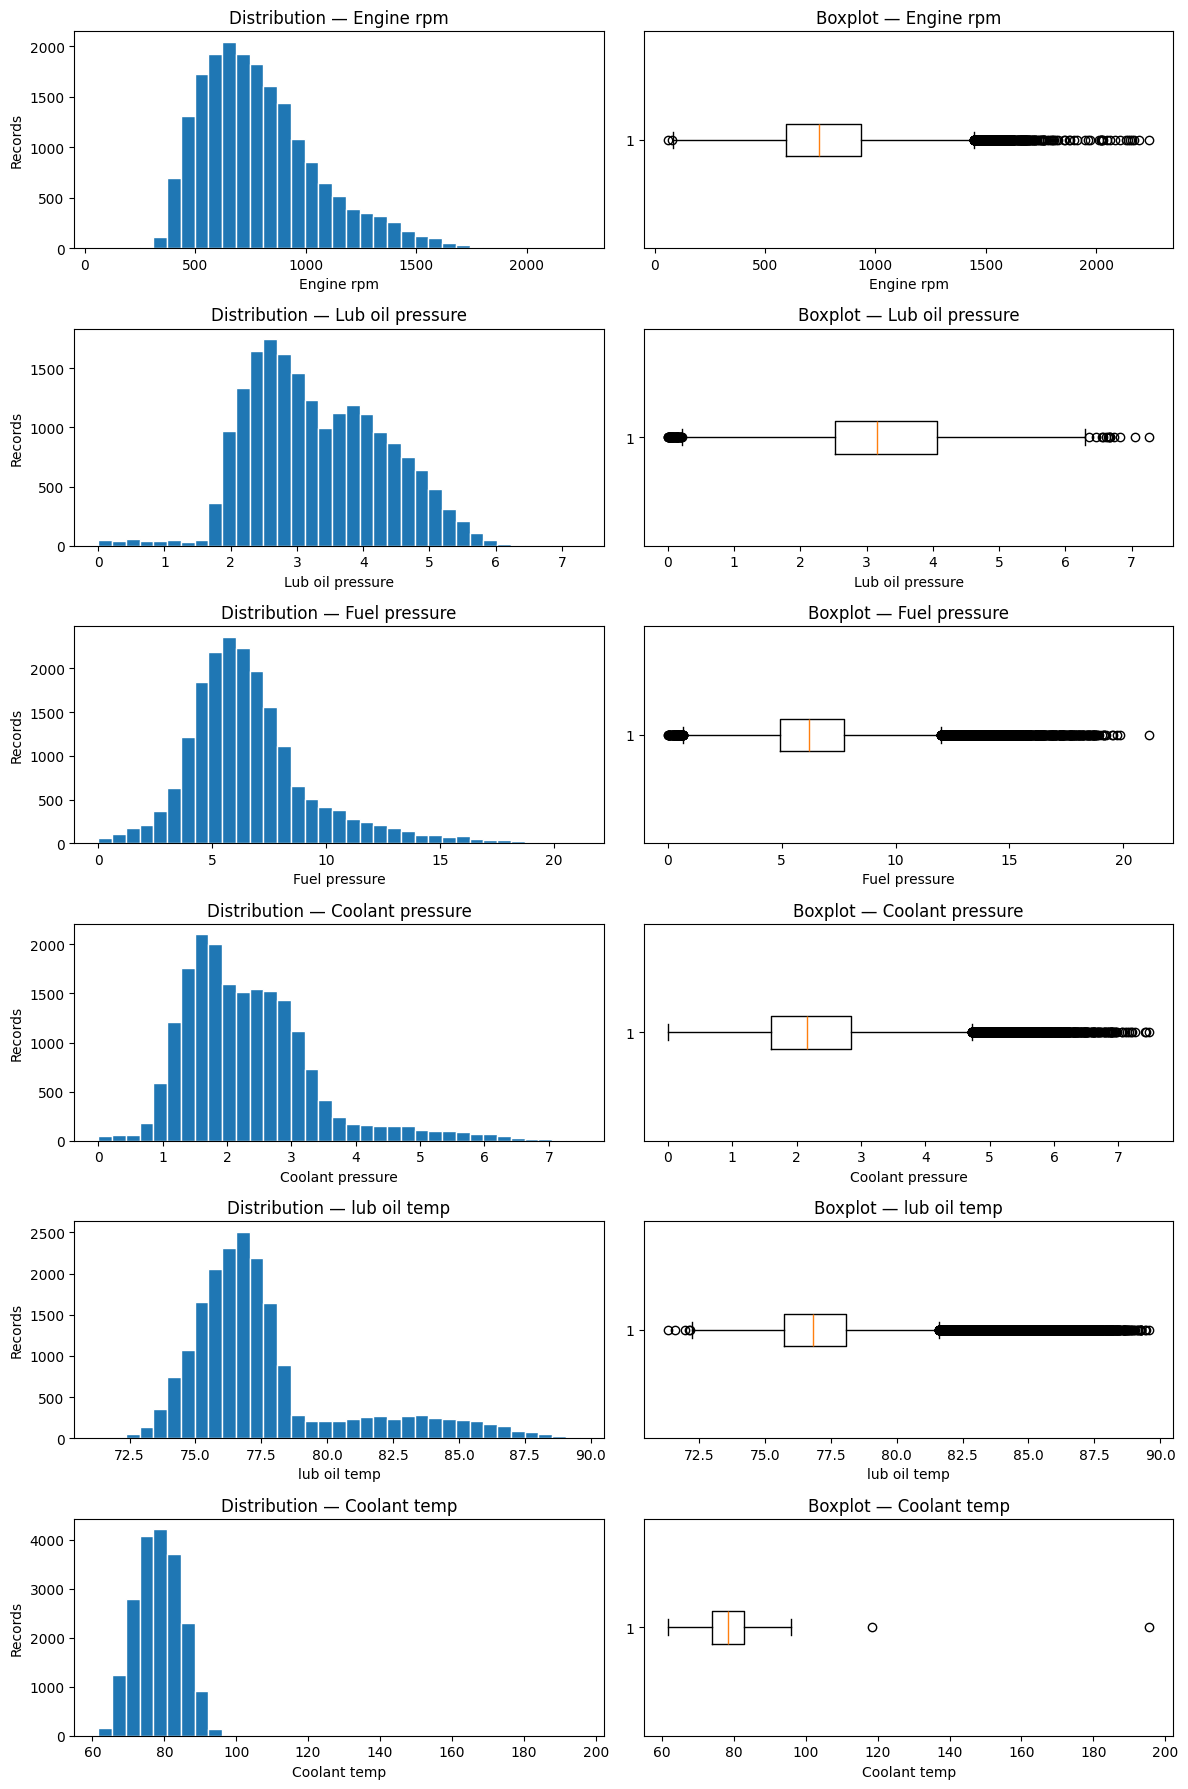

,sensor,iqr_flagged_rows,share_percent,lower_fence,upper_fence
0,Engine rpm,464,2.38,81.500000,1445.500000
1,Lub oil pressure,66,0.34,0.214130,6.359957
2,Fuel pressure,1135,5.81,0.674755,11.987104
3,Coolant pressure,785,4.02,-0.272095,4.721400
4,lub oil temp,2617,13.40,72.207440,81.590241
5,Coolant temp,2,0.01,60.365435,96.445397


Decision: retain IQR-flagged records pending engineering validation.


In [4]:
fig, axes = plt.subplots(len(FEATURE_COLUMNS), 2, figsize=(12, 18))
for index, feature in enumerate(FEATURE_COLUMNS):
    axes[index, 0].hist(df[feature], bins=35, edgecolor="white")
    axes[index, 0].set_title(f"Distribution — {feature}")
    axes[index, 0].set_xlabel(feature)
    axes[index, 0].set_ylabel("Records")
    axes[index, 1].boxplot(df[feature].dropna(), vert=False)
    axes[index, 1].set_title(f"Boxplot — {feature}")
    axes[index, 1].set_xlabel(feature)
fig.tight_layout()
display(fig)
fig.savefig(FIGURES / "sensor_distributions.png", dpi=180, bbox_inches="tight")
plt.close(fig)

outlier_rows = []
for feature in FEATURE_COLUMNS:
    q1, q3 = df[feature].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df[feature] < lower) | (df[feature] > upper)).sum())
    outlier_rows.append({
        "sensor": feature,
        "iqr_flagged_rows": count,
        "share_percent": round(count / len(df) * 100, 2),
        "lower_fence": lower,
        "upper_fence": upper,
    })
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)
print("Decision: retain IQR-flagged records pending engineering validation.")

## 5. Bivariate and multivariate analysis
Class-wise boxplots and a Pearson correlation matrix are used to inspect differences and linear associations. Correlation is descriptive and is not interpreted as causation.

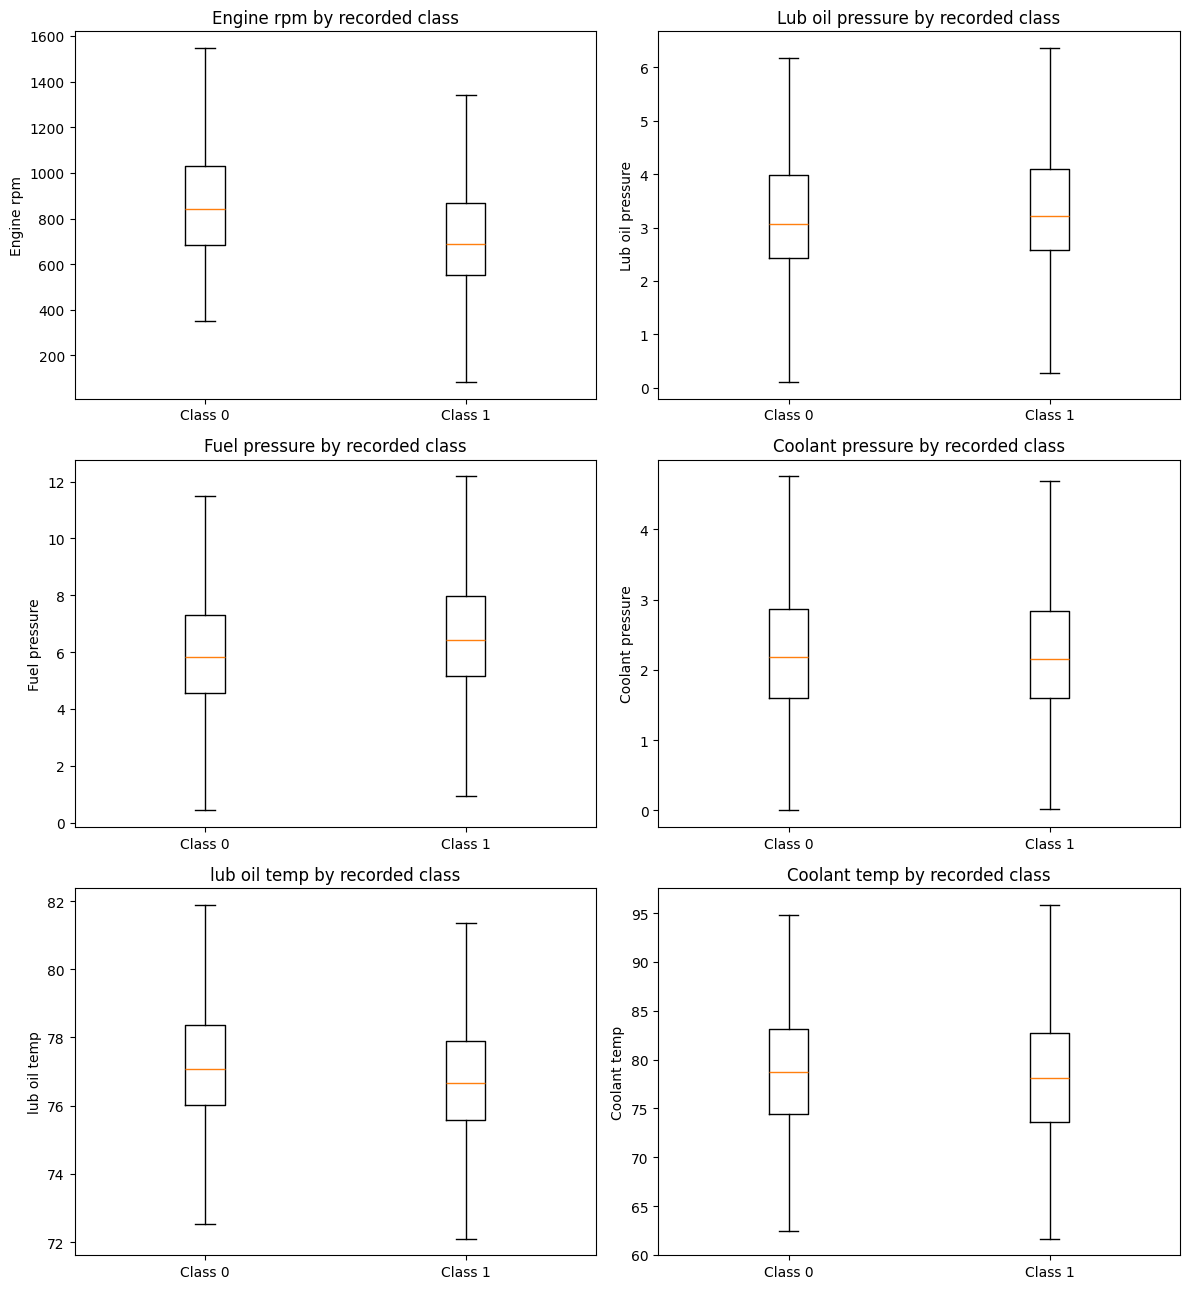

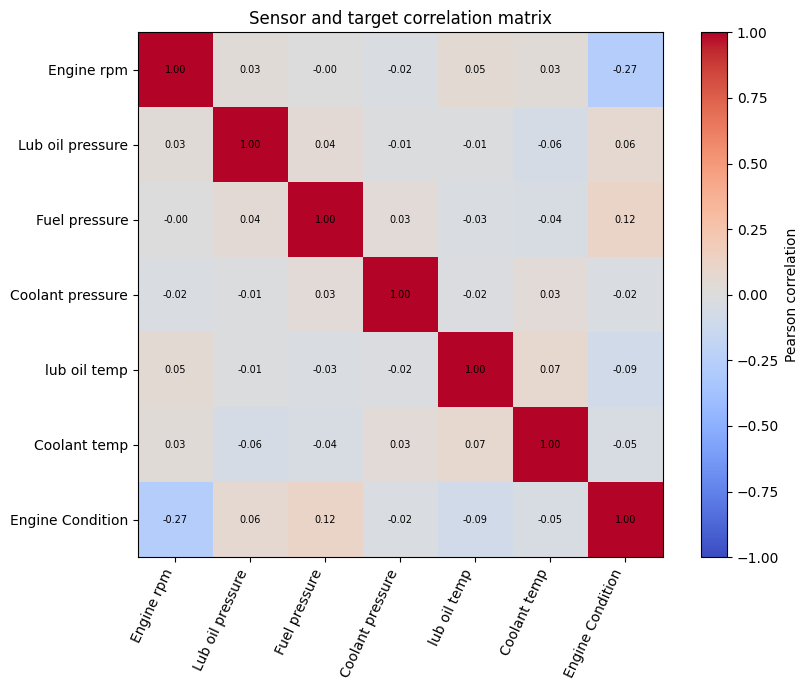

,correlation_with_target
Engine rpm,-0.268201
Fuel pressure,0.116259
lub oil temp,-0.093635
Lub oil pressure,0.060904
Coolant temp,-0.046326
Coolant pressure,-0.024054


In [5]:
fig, axes = plt.subplots(3, 2, figsize=(12, 13))
for ax, feature in zip(axes.flat, FEATURE_COLUMNS):
    grouped = [df.loc[df[TARGET] == label, feature].values for label in [0, 1]]
    ax.boxplot(grouped, labels=["Class 0", "Class 1"], showfliers=False)
    ax.set_title(f"{feature} by recorded class")
    ax.set_ylabel(feature)
fig.tight_layout()
display(fig)
fig.savefig(FIGURES / "classwise_sensor_boxplots.png", dpi=180, bbox_inches="tight")
plt.close(fig)

correlation = df[EXPECTED_COLUMNS].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=65, ha="right")
ax.set_yticks(range(len(correlation.index)), correlation.index)
for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Sensor and target correlation matrix")
fig.tight_layout()
display(fig)
fig.savefig(FIGURES / "correlation_matrix.png", dpi=180, bbox_inches="tight")
plt.close(fig)
target_correlations = correlation[TARGET].drop(TARGET).sort_values(key=lambda values: values.abs(), ascending=False)
display(target_correlations.to_frame("correlation_with_target"))

## 6. Data preparation and workflow artifact hand-off
The data is split once using an 80/20 stratified split and random state 42. The preparation job saves the partitions locally, packages them in a ZIP artifact and reloads the files from that archive to verify the downstream hand-off.

In [6]:
from prepare_data import prepare

workflow_artifact = prepare()
with zipfile.ZipFile(workflow_artifact) as archive:
    train_df = pd.read_csv(archive.open("train.csv"))
    test_df = pd.read_csv(archive.open("test.csv"))
    split_metadata = json.load(archive.open("split_metadata.json"))
print("Workflow artifact:", workflow_artifact)
print("Train shape:", train_df.shape, "| Test shape:", test_df.shape)
display(pd.DataFrame({
    "training_class_share": train_df[TARGET].value_counts(normalize=True).sort_index(),
    "holdout_class_share": test_df[TARGET].value_counts(normalize=True).sort_index(),
}))
print("Split metadata:", json.dumps(split_metadata, indent=2))

DATA VALIDATION: PASSED
{
  "file": "/mnt/data/pm_audit/Predictive_Maintenance/data/engine_data.csv",
  "rows": 19535,
  "columns": 7,
  "predictor_columns": [
    "Engine rpm",
    "Lub oil pressure",
    "Fuel pressure",
    "Coolant pressure",
    "lub oil temp",
    "Coolant temp"
  ],
  "target": "Engine Condition",
  "missing_cells": 0,
  "duplicate_rows": 0,
  "target_counts": {
    "0": 7218,
    "1": 12317
  }
}


Train rows: 15,628; test rows: 3,907
Workflow artifact verified: /mnt/data/pm_audit/Predictive_Maintenance/artifacts/train_test_workflow_artifact.zip
Workflow artifact: /mnt/data/pm_audit/Predictive_Maintenance/artifacts/train_test_workflow_artifact.zip
Train shape: (15628, 7) | Test shape: (3907, 7)


,training_class_share,holdout_class_share
Engine Condition,,
0,0.369465,0.369593
1,0.630535,0.630407


Split metadata: {
  "source_file": "data/engine_data.csv",
  "rows_total": 19535,
  "train_rows": 15628,
  "test_rows": 3907,
  "test_size": 0.2,
  "random_state": 42,
  "stratified": true,
  "features": [
    "Engine rpm",
    "Lub oil pressure",
    "Fuel pressure",
    "Coolant pressure",
    "lub oil temp",
    "Coolant temp"
  ],
  "target": "Engine Condition"
}


## 7. Model tuning and experiment tracking
The training module evaluates Random Forest, Extra Trees and Gradient Boosting using `RandomizedSearchCV` with three-fold stratified cross-validation. The baseline is evaluated on training-only folds. Within each search, mean class-1 recall is the primary selection criterion and mean class-1 F1 is the tie-break. The hold-out set is reserved for the selected model's final evaluation.

In [7]:
from train_model import run_training

experiments, final_metrics, best_model, baseline_metrics = run_training(workflow_artifact)
display(experiments)
display(pd.DataFrame([baseline_metrics]))
print("Selected model:", final_metrics["selected_model"])

TRAINING-ONLY CROSS-VALIDATION RESULTS
            model  best_cv_recall_class1  cv_recall_std  best_cv_f1_class1  best_cv_roc_auc                                                                                          best_params  search_iterations  cv_folds                                       selection_rule
Gradient Boosting               0.949664       0.010628           0.774934         0.687674 {"learning_rate": 0.08, "max_depth": 1, "min_samples_leaf": 1, "n_estimators": 35, "subsample": 1.0}                  3         3 max mean recall_class1; tie-break max mean f1_class1
    Random Forest               0.751571       0.012217           0.731020         0.676289               {"max_depth": null, "max_features": "sqrt", "min_samples_leaf": 3, "n_estimators": 35}                  3         3 max mean recall_class1; tie-break max mean f1_class1
      Extra Trees               0.677591       0.015352           0.709588         0.692587               {"max_depth": null, "max_featu

,model,best_cv_recall_class1,cv_recall_std,best_cv_f1_class1,best_cv_roc_auc,best_params,search_iterations,cv_folds,selection_rule
0,Gradient Boosting,0.949664,0.010628,0.774934,0.687674,"{""learning_rate"": 0.08, ""max_depth"": 1, ""min_s...",3,3,max mean recall_class1; tie-break max mean f1_...
1,Random Forest,0.751571,0.012217,0.731020,0.676289,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",3,3,max mean recall_class1; tie-break max mean f1_...
2,Extra Trees,0.677591,0.015352,0.709588,0.692587,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",3,3,max mean recall_class1; tie-break max mean f1_...


,model,cv_recall_class1_mean,cv_recall_class1_std,cv_f1_class1_mean,cv_roc_auc_mean
0,DummyClassifier (most_frequent),1.0,0.0,0.773409,0.5


Selected model: Gradient Boosting


## 8. Final hold-out evaluation and error analysis
Only the selected estimator is evaluated on the untouched 20% hold-out partition. Accuracy, class-specific precision/recall/F1, balanced accuracy, macro F1, ROC-AUC and average precision are reported alongside the confusion matrix.

In [8]:
metrics_path = ARTIFACTS / "holdout_test_metrics.json"
metrics = json.loads(metrics_path.read_text())
display(pd.DataFrame([{
    key: value for key, value in metrics.items()
    if key not in ["confusion_matrix_labels_0_1", "classification_report"]
}]).T.rename(columns={0: "value"}))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
display(pd.DataFrame(
    metrics["confusion_matrix_labels_0_1"],
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"],
))
display(pd.DataFrame(metrics["classification_report"]).T.round(4))

,value
selected_model,Gradient Boosting
test_rows,3907
test_accuracy,0.65421
test_balanced_accuracy,0.54839
test_precision_class0,0.645768
test_recall_class0,0.142659
test_f1_class0,0.233693
test_precision_class1,0.654961
test_recall_class1,0.954121
test_f1_class1,0.776731


Confusion matrix [[TN, FP], [FN, TP]]:


,Predicted 0,Predicted 1
Actual 0,206,1238
Actual 1,113,2350


,precision,recall,f1-score,support
0,0.6458,0.1427,0.2337,1444.0000
1,0.6550,0.9541,0.7767,2463.0000
accuracy,0.6542,0.6542,0.6542,0.6542
macro avg,0.6504,0.5484,0.5052,3907.0000
weighted avg,0.6516,0.6542,0.5760,3907.0000


## 9. Model diagnostics and explainability
The confusion matrix, ROC curve and impurity-based feature importance are reviewed together. Feature importance is model-specific and does not establish causal effects.

final_confusion_matrix.png


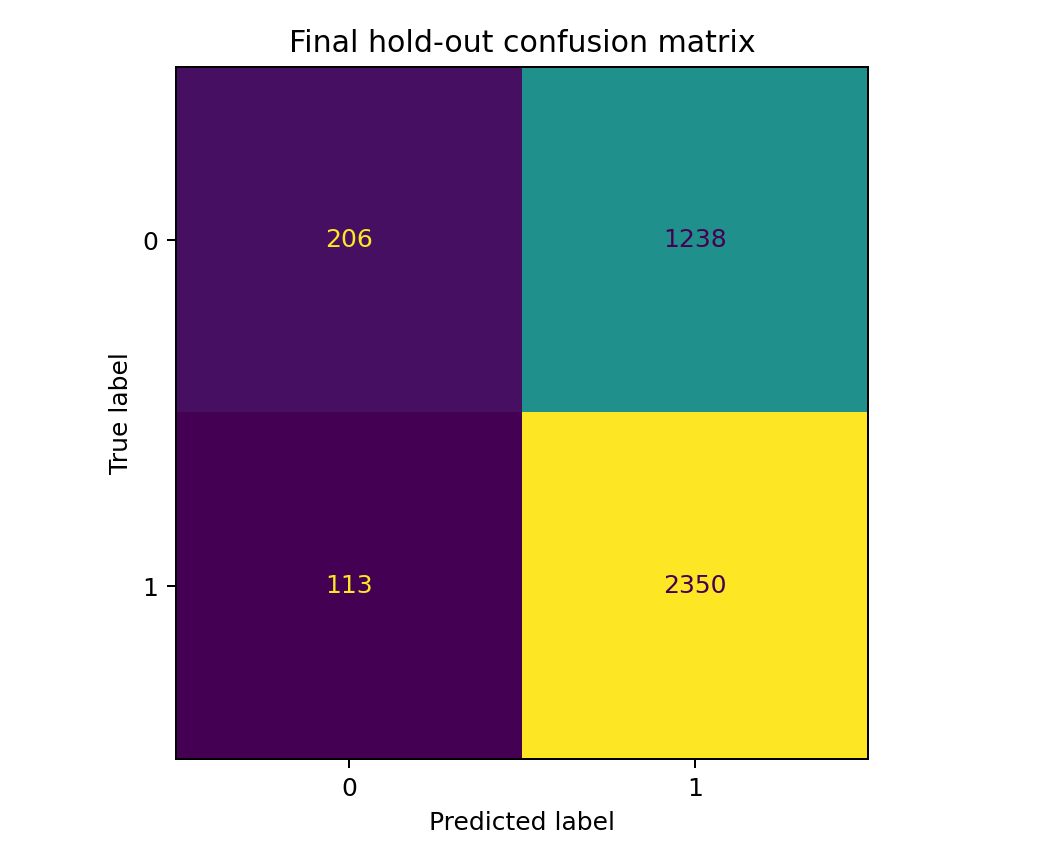

final_roc_curve.png


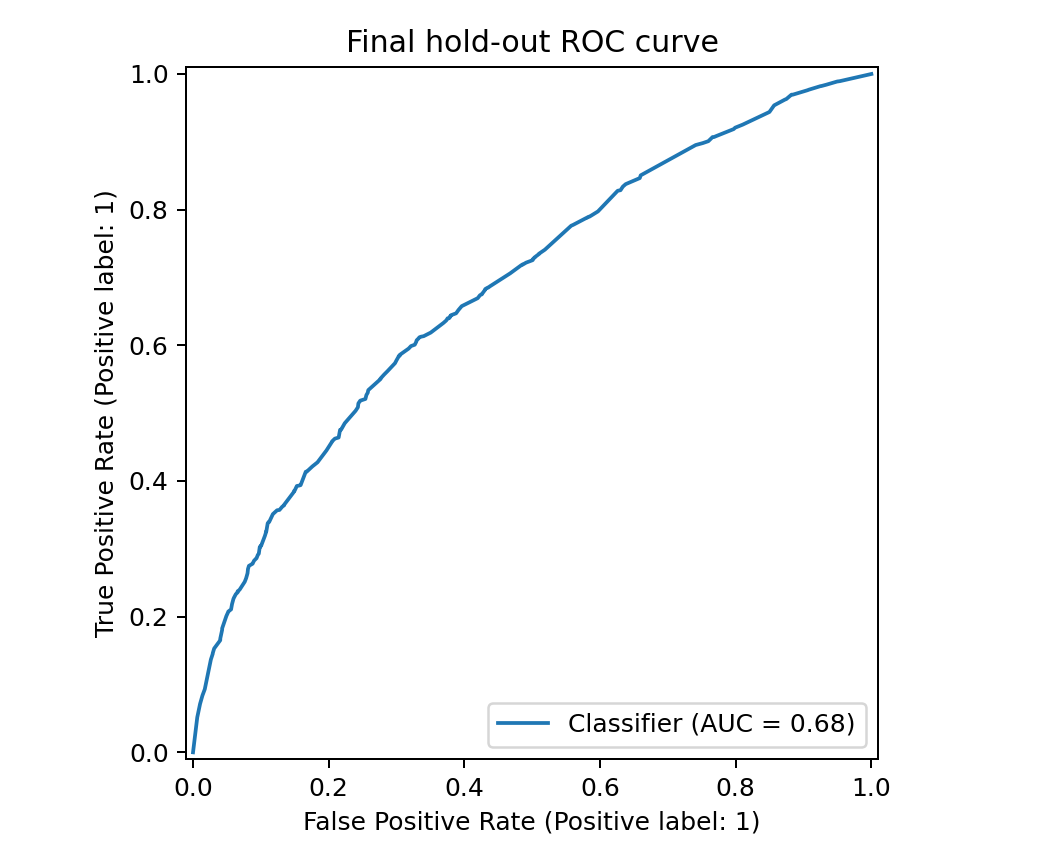

feature_importance.png


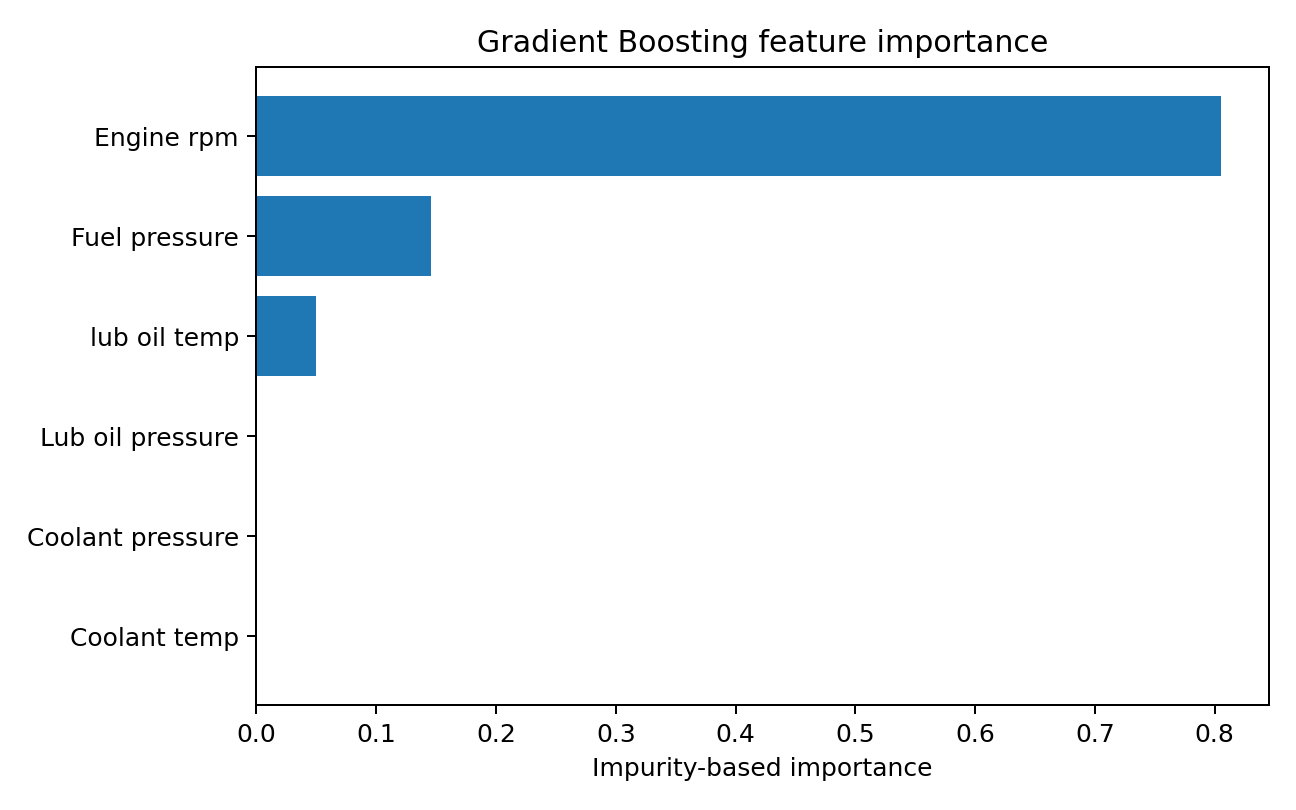

,feature,importance
0,Engine rpm,0.805098
1,Fuel pressure,0.145515
2,lub oil temp,0.049387
3,Lub oil pressure,0.000000
4,Coolant pressure,0.000000
5,Coolant temp,0.000000


In [9]:
for filename in ["final_confusion_matrix.png", "final_roc_curve.png", "feature_importance.png"]:
    figure_path = FIGURES / filename
    if figure_path.is_file():
        print(filename)
        display(Image(filename=str(figure_path)))
importance = pd.read_csv(ARTIFACTS / "feature_importance.csv")
display(importance)

## 10. Model registration and Streamlit application validation
The selected estimator and metadata are persisted for inference. The app source is syntax-checked and the registered estimator is loaded to verify that the expected six-column input frame produces a valid numeric prediction and probability vector.

In [10]:
model_path = ARTIFACTS / "best_model.joblib"
metadata_path = ARTIFACTS / "model_metadata.json"
assert model_path.is_file() and metadata_path.is_file()
registered_model = joblib.load(model_path)
model_metadata = json.loads(metadata_path.read_text())
sample_frame = df[model_metadata["features"]].head(3)
sample_predictions = registered_model.predict(sample_frame)
sample_probabilities = registered_model.predict_proba(sample_frame)
print("Registered model:", model_metadata["model_name"])
print("Feature order:", model_metadata["features"])
print("Sample predictions:", sample_predictions.tolist())
print("Probability output shape:", sample_probabilities.shape)
app_source = (ROOT / "app.py").read_text()
compile(app_source, str(ROOT / "app.py"), "exec")
print("Streamlit app syntax check: PASSED")

Registered model: Gradient Boosting
Feature order: ['Engine rpm', 'Lub oil pressure', 'Fuel pressure', 'Coolant pressure', 'lub oil temp', 'Coolant temp']
Sample predictions: [1, 1, 1]
Probability output shape: (3, 2)
Streamlit app syntax check: PASSED


## 11. GitHub Actions workflow validation
The workflow contains two dependent jobs. The first validates the dataset, creates the stratified partitions and uploads a workflow artifact. The second downloads the artifact, runs tuning and evaluation, and commits refreshed model and experiment artifacts to `main` when triggered on that branch.

In [11]:
import yaml
workflow_path = ROOT / ".github" / "workflows" / "pipeline.yml"
workflow_text = workflow_path.read_text()
workflow_config = yaml.safe_load(workflow_text)
required_terms = [
    "actions/checkout", "actions/setup-python", "actions/upload-artifact",
    "actions/download-artifact", "python src/validate_data.py",
    "python src/prepare_data.py", "python src/train_model.py",
    "git push origin HEAD:main",
]
workflow_checks = {term: term in workflow_text for term in required_terms}
display(pd.Series(workflow_checks, name="present").to_frame())
assert all(workflow_checks.values())
assert "prepare-data" in workflow_config["jobs"]
assert "train-evaluate-register" in workflow_config["jobs"]
assert workflow_config["jobs"]["train-evaluate-register"]["needs"] == "prepare-data"
print("Workflow structure and required hand-off checks: PASSED")

,present
actions/checkout,True
actions/setup-python,True
actions/upload-artifact,True
actions/download-artifact,True
python src/validate_data.py,True
python src/prepare_data.py,True
python src/train_model.py,True
git push origin HEAD:main,True


Workflow structure and required hand-off checks: PASSED


## 12. Reproducibility summary and generated artifacts
The output inventory lists the saved model, metadata, full tuning logs, baseline CV result, hold-out metrics, split archive and diagnostic figures. The public GitHub workflow run and Streamlit Community Cloud deployment must be verified from the learner's accounts; local validation is not a substitute for those live outputs.

In [12]:
artifact_files = sorted(
    str(path.relative_to(ROOT))
    for path in ROOT.rglob("*")
    if path.is_file() and "__pycache__" not in path.parts
)
display(pd.DataFrame({"generated_project_file": artifact_files}))
print("Final selected model:", metrics["selected_model"])
print("Hold-out accuracy:", round(metrics["test_accuracy"], 4))
print("Hold-out class-1 recall:", round(metrics["test_recall_class1"], 4))
print("Hold-out class-0 recall:", round(metrics["test_recall_class0"], 4))
print("Hold-out ROC-AUC:", round(metrics["test_roc_auc"], 4))

,generated_project_file
0,.github/workflows/pipeline.yml
1,.gitignore
2,.python-version
3,Muthu_Aravind_Predictive_Maintenance_Notebook....
4,README.md
5,app.py
6,artifacts/baseline_cv_metrics.csv
7,artifacts/baseline_test_metrics.csv
8,artifacts/best_model.joblib
9,artifacts/best_params.json


Final selected model: Gradient Boosting
Hold-out accuracy: 0.6542
Hold-out class-1 recall: 0.9541
Hold-out class-0 recall: 0.1427
Hold-out ROC-AUC: 0.6845


## Appendix — Source files and external resources
- Dataset: `engine_data.csv`, supplied in the capstone learning materials; no external dataset was merged.
- Reusable implementation: `src/validate_data.py`, `src/prepare_data.py`, `src/train_model.py`.
- Inference interface: `app.py`.
- Automation: `.github/workflows/pipeline.yml`.
- Full tuning result tables and model artifacts: `artifacts/`.
- The notebook was executed against the source modules included in the companion project ZIP. The final PDF intentionally contains no raw code; the executed HTML notebook is the code-verification deliverable.